# 04 · Thin-file second look (Issue #13)

## Where this notebook sits
```
model_building/01_primary_model   stage 1: logistic regression decides first (approve if PD < 20%)
model_building/02_lightgbm        LightGBM + per-segment calibration (the general second-look model)
model_building/03_second_look     stage 2: every applicant stage 1 rejects is re-scored by 02's model
model_building/04_thin_file_second_look   ◄── this notebook: a separate path for thin-file applicants inside stage 2
```

**Why this notebook exists.** Our Challenge Advisor described the design as:

1. **Model 1** checks every applicant and approves or declines them.
2. **Every applicant model 1 rejects** gets a second look from **model 2**, which checks whether they are thin-file.
3. **Thin-file applicants** get a different check that looks at *background and other information*, and **some percentage** of them is approved.

Notebooks 01–03 (PR #25) build steps 1 and 2: every rejected applicant, thin-file or established, is re-scored by the same calibrated
LightGBM. This notebook tests the two ways step 3 could add something:

| Question | Section |
|---|---|
| **A.** Can a model built *only for thin-file applicants*, with extra background features from the tax, previous-application and person tables, rank them better than the general model? | §3–4 |
| **B.** How many rejected thin-file applicants can the second look approve, and what does each choice cost in risk and profit? (the "some percentage") | §5 |

**Honest-evaluation rules** (same as notebooks 01–03): train on weeks 0–67, make every choice on weeks 68–79, report on weeks 80–91 once.
`solution.csv` is never opened.

**Run first:** `python run_pipeline.py`, then `01_primary_model.ipynb` (writes `artifacts/primary_predictions_*.parquet`).
The general model's scores come from the committed models in `lightgbm/models/` through `lightgbm/score.py`, so notebook 02 does not need to be re-run.

## 1. Setup and load

In [1]:
# Setup: libraries, paths, the week split and the shared scoring rules.
from pathlib import Path
import json
import sys
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from policy_metrics import CUTOFF, evaluate_decisions   # shared scoring rules (same folder)

warnings.filterwarnings("ignore", message="Overriding the parameters from Reference Dataset")

ROOT = Path.cwd().parent.parent          # notebooks/model_building -> repo root
PROCESSED = ROOT / "data" / "processed"
RAW = ROOT / "data" / "raw" / "csv_files" / "train"
ART = Path.cwd() / "artifacts"           # stage-1 outputs from notebook 01
LGB_DIR = Path.cwd() / "lightgbm"        # committed LightGBM models from notebook 02

sys.path.insert(0, str(LGB_DIR))
from score import score as general_score  # the calibrated general second-look model (design C in notebook 03)

SEED = 42
ES_START_WEEK = 56                       # early stopping for the thin-file models uses weeks 56-67 ...
TUNE_START_WEEK = 68                     # ... so weeks 68-79 stay a clean judge for every choice
VALID_START_WEEK = 80                    # weeks 80-91: reported once

In [2]:
# One row per applicant (weeks 0-91): notebook 04's features + stage-1 decisions (notebook 01) + the general model's PD.
feat = pd.read_parquet(PROCESSED / "features_train.parquet")
s1 = pd.concat([pd.read_parquet(ART / f"primary_predictions_{name}.parquet") for name in ("fit", "valid")])
df = feat.merge(s1[["case_id", "pd_primary", "primary_approve"]], on="case_id", validate="one_to_one")
assert len(df) == len(feat), "run 01_primary_model.ipynb first: stage-1 predictions are missing for some applicants"
df["pd_general"] = general_score(df)     # weeks 0-67 LightGBM + per-segment Platt calibration (fitted on 68-79)

w, y = df["WEEK_NUM"].to_numpy(), df["target"].to_numpy()
thin = df["thin_file"].to_numpy() == 1
s1_approve = df["primary_approve"].to_numpy()
rejected = ~s1_approve
p_general = df["pd_general"].to_numpy()
TR, TU, VA = w < TUNE_START_WEEK, (w >= TUNE_START_WEEK) & (w < VALID_START_WEEK), w >= VALID_START_WEEK


def two_stage(p_thin_branch, thin_cutoff=CUTOFF):
    # Stage 1 approvals are final. Rejected established applicants: general model at 20%.
    # Rejected thin-file applicants: p_thin_branch at thin_cutoff (the thin-file path of the second look).
    rescued = rejected & ((~thin & (p_general < CUTOFF)) | (thin & (p_thin_branch < thin_cutoff)))
    return s1_approve | rescued


check = evaluate_decisions(y[VA], two_stage(p_general)[VA], thin[VA])
print(f"{len(df):,} applicants | train weeks 0-67: {TR.sum():,} | tune 68-79: {TU.sum():,} | valid 80-91: {VA.sum():,}")
print(f"design C rebuilt on weeks 80-91: profit ${check['Profit $M']:.2f}M, inclusion gap {check['Inclusion gap pp']:.1f} pp "
      f"(notebook 03 / PR #25: $96.0M, 16.2 pp)")

1,000,000 applicants | train weeks 0-67: 739,183 | tune 68-79: 130,376 | valid 80-91: 130,441
design C rebuilt on weeks 80-91: profit $96.00M, inclusion gap 16.2 pp (notebook 03 / PR #25: $96.0M, 16.2 pp)


## 2. Who reaches the thin-file path?

Everyone stage 1 rejects gets a second look. This is the group step 3 is about: rejected **thin-file** applicants, next to the rejected
established applicants for comparison (weeks 80–91).

In [3]:
rows = {}
for name, seg in [("rejected thin-file", thin), ("rejected established", ~thin)]:
    m = VA & rejected & seg
    rescued_now = m & (p_general < CUTOFF)
    rows[name] = {"applicants": m.sum(), "share of their segment rejected %": m.sum() / (VA & seg).sum() * 100,
                  "actual default %": y[m].mean() * 100, "would have repaid": (m & (y == 0)).sum(),
                  "approved by today's second look": rescued_now.sum(),
                  "default % of those approved": y[rescued_now].mean() * 100}
pd.DataFrame(rows).T.round(1)

,applicants,share of their segment rejected %,actual default %,would have repaid,approved by today's second look,default % of those approved
rejected thin-file,25301.0,64.9,26.0,18714.0,9030.0,16.5
rejected established,26251.0,28.7,36.1,16762.0,2208.0,17.0


**What this shows.** Stage 1 rejects about two-thirds of thin-file applicants but under a third of established ones, and most rejected
thin-file applicants would actually have repaid. Today's second look (the calibrated general model) already approves the safest of them,
at a default rate below the 20% break-even point.

## 3. Question A: does a thin-file-only model with background features rank better?

The CA's idea is that thin-file applicants need a check based on **other information**. Their credit-bureau features are empty
(23 of 55 features are constant for them, computed below), so the only background information we have is in three tables:

| Table | What it holds | Already in notebook 04's features | New here |
|---|---|---|---|
| `tax_registry_a_1` | declared tax amounts, masked employer code | count, sum, mean, max, employer count, tax-to-income | min, spread (std), share of records from the main employer |
| `applprev_1` | previous applications: amount, approval date, status | count, amounts, days since first/last approval, status counts | approved count/share, approvals in the last 2 years, smallest previous amount |
| `person_1` | income, employment length, housing per person | sum/max income, mean employment | the main applicant's own income and employment |

Plus ratios that compare background with the loan: tax-to-annuity, tax-to-credit, previous-to-current credit, income-to-tax.

**Three models are compared on the same applicants:**
1. **General** (today's second look): LightGBM trained on everyone.
2. **Thin-file only**: the same LightGBM settings, trained only on thin-file applicants, on their 32 usable features.
3. **Thin-file only + background**: the same, plus the new features.

**Pre-set rule** (fixed before looking): a thin-file model replaces the general one only if it beats it by at least **0.005 AUC**
among rejected thin-file applicants on the tune weeks 68–79. AUC is the right test here: per-segment calibration can fix the *level* of
the probabilities afterwards, but not the *order*.

In [4]:
# New background features, built from the raw tables and joined one row per applicant.
def background_features(raw_dir, base):
    tax = pd.read_csv(raw_dir / "train_tax_registry_a_1.csv")
    g = tax.groupby("case_id")
    main_employer = tax.groupby(["case_id", "name_4527232M"]).size().groupby("case_id").max()
    new_tax = pd.DataFrame({"tax_amount_std": g["amount_4527230A"].std(),
                            "tax_amount_min": g["amount_4527230A"].min(),
                            "tax_top_employer_share": main_employer / g.size()})

    prev = pd.read_csv(raw_dir / "train_applprev_1.csv", parse_dates=["approvaldate_319D"]).merge(base, on="case_id")
    prev["approved"] = prev["approvaldate_319D"].notna()
    prev["approved_2y"] = (prev["date_decision"] - prev["approvaldate_319D"]).dt.days.le(730)
    gp = prev.groupby("case_id")
    new_prev = pd.DataFrame({"prev_approved_count": gp["approved"].sum(), "prev_approved_share": gp["approved"].mean(),
                             "prev_approved_2y_count": gp["approved_2y"].sum(),
                             "prev_credamount_min": gp["credamount_590A"].min()})

    person = pd.read_csv(raw_dir / "train_person_1.csv")
    main = person[person["personindex_1023L"] == 0].set_index("case_id")   # person 0 = the applicant
    new_person = pd.DataFrame({"person_applicant_income": main["mainoccupationinc_384A"],
                               "person_applicant_employed": main["empl_employedtotal_800L"]})
    return new_tax.join(new_prev, how="outer").join(new_person, how="outer")


base = pd.read_csv(RAW / "train_base.csv", usecols=["case_id", "date_decision"], parse_dates=["date_decision"])
bg = background_features(RAW, base)
df = df.merge(bg, left_on="case_id", right_index=True, how="left", validate="one_to_one")
df["tax_to_annuity"] = df["tax_amount_mean"] / df["annuity_780A"]
df["tax_to_credit"] = df["tax_amount_mean"] / df["credamount_770A"]
df["prev_to_current_credit"] = df["prev_credamount_mean"] / df["credamount_770A"]
df["income_to_tax"] = df["mainoccupationinc_384A"] / df["tax_amount_mean"]
BACKGROUND = list(bg.columns) + ["tax_to_annuity", "tax_to_credit", "prev_to_current_credit", "income_to_tax"]

# Features that carry nothing for thin-file applicants (constant or empty in their training weeks).
NOT_FEATURES = ["case_id", "target", "WEEK_NUM", "thin_file", "date_decision", "birth_259D",
                "pd_primary", "primary_approve", "pd_general"] + BACKGROUND
EXISTING = [c for c in feat.columns if c not in NOT_FEATURES]
dead = [c for c in EXISTING if df.loc[TR & thin, c].nunique(dropna=True) <= 1]
LIVE = [c for c in EXISTING if c not in dead]
print(f"{len(EXISTING)} existing features: {len(dead)} are constant for thin-file applicants, {len(LIVE)} usable")
print(f"{len(BACKGROUND)} new background features")

# How much signal each new feature has on its own (thin-file applicants, train weeks). 0.5 = none.
uni = {}
for c in BACKGROUND:
    m = TR & thin & df[c].notna().to_numpy()
    a = roc_auc_score(y[m], df.loc[m, c])
    uni[c] = {"AUC alone (thin-file)": max(a, 1 - a), "% of thin-file with a value": m.sum() / (TR & thin).sum() * 100}
pd.DataFrame(uni).T.sort_values("AUC alone (thin-file)", ascending=False).round(3)

55 existing features: 23 are constant for thin-file applicants, 32 usable
13 new background features


,AUC alone (thin-file),% of thin-file with a value
tax_amount_min,0.575,74.949
person_applicant_employed,0.561,80.032
person_applicant_income,0.552,94.971
prev_credamount_min,0.547,79.975
tax_to_credit,0.547,73.474
tax_to_annuity,0.546,67.522
prev_to_current_credit,0.536,78.432
tax_amount_std,0.534,50.130
prev_approved_2y_count,0.510,79.975
income_to_tax,0.506,71.202


In [5]:
# Train the two thin-file-only models (weeks 0-55, early stopping on 56-67) and judge all three on the tune weeks 68-79.
params = json.load(open(LGB_DIR / "params" / "best_params.json"))["lightgbm"]["params"]   # notebook 02's settings
CATS = {c: sorted(df[c].dropna().unique()) for c in LIVE if not pd.api.types.is_numeric_dtype(df[c])}


def prepare(frame, cols):
    X = frame[cols].copy()
    for c, cats in CATS.items():
        if c in X:
            X[c] = pd.Categorical(X[c], categories=cats)
    return X


def train_thin_model(cols):
    tr, es = TR & thin & (w < ES_START_WEEK), TR & thin & (w >= ES_START_WEEK)
    d_tr = lgb.Dataset(prepare(df[tr], cols), y[tr], params={"feature_pre_filter": False})
    d_es = lgb.Dataset(prepare(df[es], cols), y[es], reference=d_tr)
    model = lgb.train(params, d_tr, num_boost_round=5000, valid_sets=[d_es],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
    return model, model.predict(prepare(df, cols), num_iteration=model.best_iteration)


t = time.time()
thin_model, p_thin = train_thin_model(LIVE)
thin_bg_model, p_thin_bg = train_thin_model(LIVE + BACKGROUND)
print(f"trained both thin-file models in {time.time() - t:.0f}s "
      f"({thin_model.best_iteration} and {thin_bg_model.best_iteration} trees)")

candidates = {"General (today's second look)": p_general, "Thin-file only": p_thin, "Thin-file only + background": p_thin_bg}
auc = {}
for name, p in candidates.items():
    auc[name] = {"tune AUC: rejected thin-file": roc_auc_score(y[TU & rejected & thin], p[TU & rejected & thin]),
                 "tune AUC: all thin-file": roc_auc_score(y[TU & thin], p[TU & thin])}
auc = pd.DataFrame(auc).T
gain = auc["tune AUC: rejected thin-file"] - auc.loc["General (today's second look)", "tune AUC: rejected thin-file"]
auc["gain vs general"] = gain
auc["passes the +0.005 rule"] = gain >= 0.005
auc.round(4)

trained both thin-file models in 8s (153 and 225 trees)


,tune AUC: rejected thin-file,tune AUC: all thin-file,gain vs general,passes the +0.005 rule
General (today's second look),0.6532,0.7155,0.0000,False
Thin-file only,0.6527,0.7154,-0.0004,False
Thin-file only + background,0.6518,0.7147,-0.0014,False


In [6]:
# Reported once on weeks 80-91, for transparency (the decision above was made on weeks 68-79).
pd.DataFrame({name: {"valid AUC: rejected thin-file": roc_auc_score(y[VA & rejected & thin], p[VA & rejected & thin]),
                     "valid AUC: all thin-file": roc_auc_score(y[VA & thin], p[VA & thin])}
              for name, p in candidates.items()}).T.round(4)

,valid AUC: rejected thin-file,valid AUC: all thin-file
General (today's second look),0.6456,0.7071
Thin-file only,0.6450,0.7068
Thin-file only + background,0.6440,0.7064


## 4. What the thin-file model relies on

Feature importance (share of the model's total gain) for the thin-file model with background features. This is also the starting point
for explaining a thin-file decision to an applicant (technical report §13).

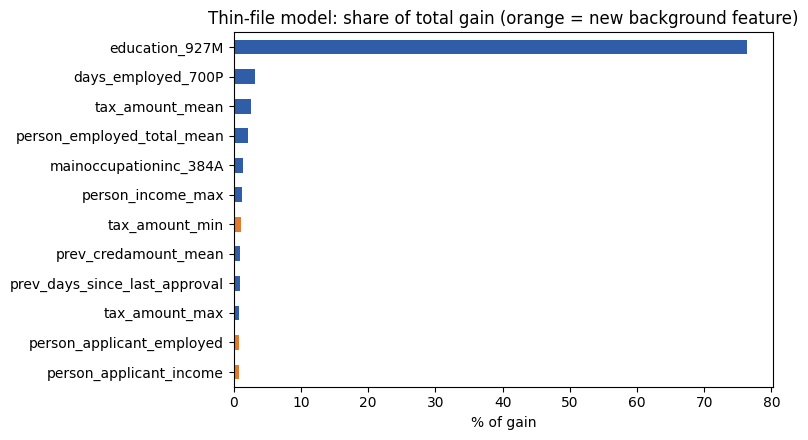

,% of gain
education_927M,76.4
days_employed_700P,3.1
tax_amount_mean,2.6
person_employed_total_mean,2.1
mainoccupationinc_384A,1.3
person_income_max,1.2
tax_amount_min,1.1
prev_credamount_mean,0.9
prev_days_since_last_approval,0.9
tax_amount_max,0.8


In [7]:
imp = pd.Series(thin_bg_model.feature_importance("gain"), index=LIVE + BACKGROUND)
imp = (imp / imp.sum() * 100).sort_values(ascending=False).head(12)
ax = imp[::-1].plot.barh(figsize=(8, 4.5), color=["#E07A2E" if c in BACKGROUND else "#2F5DA8" for c in imp.index[::-1]])
ax.set(title="Thin-file model: share of total gain (orange = new background feature)", xlabel="% of gain")
plt.tight_layout(); plt.show()
imp.round(1).to_frame("% of gain")

**What §3–4 show.**
- **No thin-file model passes the pre-set rule.** Among rejected thin-file applicants on the tune weeks, the general model scores AUC 0.6532,
  the thin-file-only model 0.6527 and the version with background features 0.6518. Weeks 80–91 tell the same story.
- **The new background features carry little on their own** (best: `tax_amount_min`, AUC 0.575) and repeat what the existing tax,
  employment and income features already say.
- **Education dominates** the thin-file model (~76% of its gain). It is the one strong signal left once bureau history is gone, which is
  worth knowing for explanations and fairness.
- So the thin-file path keeps today's **general calibrated model**. The remaining question is how many of its applicants to approve (§5).

## 5. Question B: how many rejected thin-file applicants should the second look approve?

The general model ranks rejected thin-file applicants as well as anything we can build (§3), so the remaining lever is **how many of them
to approve**. Today the thin-file path uses the same 20% cut-off as everyone else. Here only the **thin-file path's cut-off** moves;
stage 1 and the established path stay at 20%.

For each cut-off: the share of rejected thin-file applicants approved (the CA's "some percentage"), their actual default rate, and what
it does to the whole portfolio.

- **Choose on weeks 68–79** (left table), **report on 80–91** (right table, descriptive).
- Caveat: on weeks 68–79, stage 1's decisions are in-sample (its model was trained on weeks 0–79) and the per-segment calibration was fitted
  on these weeks, so the 68–79 numbers are slightly optimistic. The 80–91 numbers are clean.
- **The final pick needs the portfolio default-rate ceiling from the CA** (README, technical report §10). Without it, the profit-maximizing
  cut-off is the natural default.

most profitable thin-file cut-off on weeks 68-79: 0.20


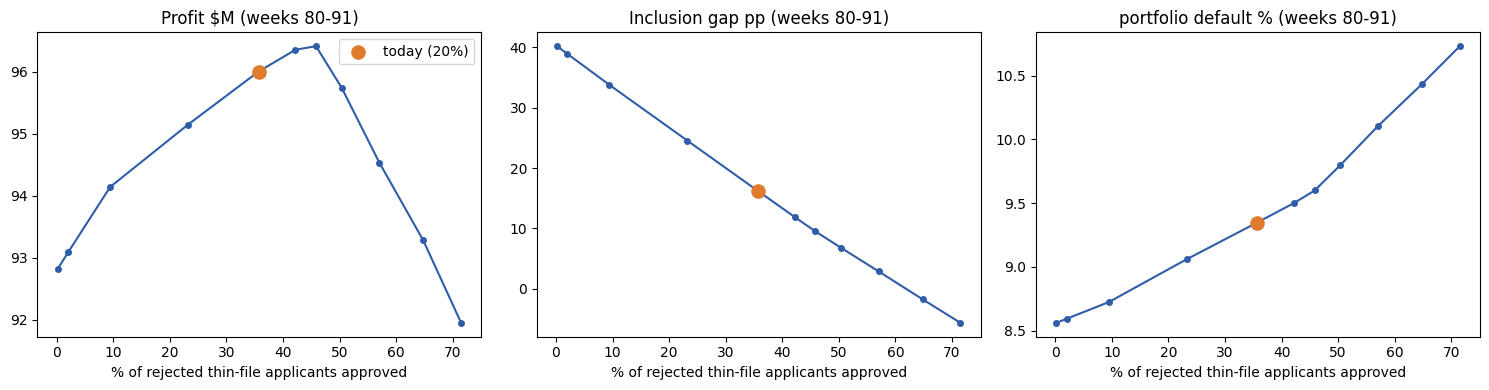

choose: weeks 68-79                  \
                  % of rejected thin-file approved their default %   
thin-file cut-off                                                    
0.12                                          0.15           18.92   
0.14                                          1.80           15.72   
0.16                                          8.82           16.17   
0.18                                         22.31           16.95   
0.20                                         35.69           17.39   
0.22                                         42.37           17.93   
0.24                                         45.85           18.35   
0.26                                         49.95           19.04   
0.28                                         56.91           19.94   
0.30                                         64.68           20.99   
0.32                                         71.38           21.87   

                                                                  \
                  portfolio default % Profit $M Inclusion gap pp   
thin-file cut-off                                                  
0.12                             8.61     92.02            39.98   
0.14                             8.65     92.22            38.83   
0.16                             8.81     92.88            33.96   
0.18                             9.16     93.75            24.76   
0.20                             9.50     94.40            15.70   
0.22                             9.71     94.26            11.32   
0.24                             9.84     93.95             9.12   
0.26                            10.03     93.25             6.63   
0.28                            10.33     92.10             2.40   
0.30                            10.71     90.39            -2.18   
0.32                            11.05     88.62            -6.04   

                               report: weeks 80-91                  \
                  % of rejected thin-file approved their default %   
thin-file cut-off                                                    
0.12                                          0.18           17.39   
0.14                                          2.04           14.53   
0.16                                          9.46           14.42   
0.18                                         23.20           16.01   
0.20                                         35.69           16.46   
0.22                                         42.22           16.67   
0.24                                         45.85           16.89   
0.26                                         50.37           17.69   
0.28                                         57.05           18.80   
0.30                                         64.79           19.71   
0.32                                         71.50           20.47   

                                                                  
                  portfolio default % Profit $M Inclusion gap pp  
thin-file cut-off                                                 
0.12                             8.56     92.82            40.20  
0.14                             8.59     93.09            38.92  
0.16                             8.72     94.14            33.78  
0.18                             9.06     95.15            24.56  
0.20                             9.35     96.00            16.20  
0.22                             9.50     96.36            11.87  
0.24                             9.60     96.41             9.50  
0.26                             9.80     95.74             6.79  
0.28                            10.10     94.53             2.85  
0.30                            10.43     93.28            -1.76  
0.32                            10.73     91.95            -5.67

In [8]:
def cutoff_sweep(period):
    rows = []
    branch = period & rejected & thin
    for c in np.round(np.arange(0.12, 0.321, 0.02), 2):
        approve = two_stage(p_general, c)
        r = evaluate_decisions(y[period], approve[period], thin[period])
        took = approve & branch
        rows.append({"thin-file cut-off": c,
                     "% of rejected thin-file approved": took.sum() / branch.sum() * 100,
                     "their default %": y[took].mean() * 100,
                     "portfolio default %": r["Default % approved"],
                     "Profit $M": r["Profit $M"], "Inclusion gap pp": r["Inclusion gap pp"]})
    return pd.DataFrame(rows).set_index("thin-file cut-off")


sweep_tune, sweep_valid = cutoff_sweep(TU), cutoff_sweep(VA)
best_cut = sweep_tune["Profit $M"].idxmax()
print(f"most profitable thin-file cut-off on weeks 68-79: {best_cut:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Profit $M", "Inclusion gap pp", "portfolio default %"]):
    ax.plot(sweep_valid["% of rejected thin-file approved"], sweep_valid[col], marker="o", ms=4, color="#2F5DA8")
    today = sweep_valid.loc[CUTOFF]
    ax.scatter(today["% of rejected thin-file approved"], today[col], s=90, color="#E07A2E", zorder=3, label="today (20%)")
    ax.set(xlabel="% of rejected thin-file applicants approved", title=f"{col} (weeks 80-91)")
axes[0].legend()
plt.tight_layout(); plt.show()

pd.concat({"choose: weeks 68-79": sweep_tune.round(2), "report: weeks 80-91": sweep_valid.round(2)}, axis=1)

**What this shows.**
- **The thin-file path's cut-off is a real lever.** Today (20%) the second look approves about 36% of rejected thin-file applicants.
- **On the weeks used to choose (68–79), 20% earns the most**, but a slightly wider path is cheap: 22% approves about 42% of them and
  cuts the inclusion gap from 15.7 to 11.3 points for −$0.14M; 24% approves about 46%, gap 9.1 points, for −$0.45M.
- **On weeks 80–91 (reported, not used to choose), those same cut-offs even add profit** (22%: +$0.36M, 24%: +$0.41M) while the gap falls
  to 11.9 and 9.5 points, because thin-file risk keeps falling over time (the drift in notebook 07).
- **Beyond about 26–28%** the approved thin-file applicants default near or above the 20% break-even, and profit falls quickly.
- **The cost is a slightly higher portfolio default rate** (9.35% today → 9.60% at 24%). Whether that is acceptable depends on the
  **default-rate ceiling**, and how much profit a smaller gap is worth depends on **λ** in the Inclusive Profit Score. Both come from the CA.

## 6. A first fairness check: age

Age is a protected characteristic in US credit rules (ECOA). If thin-file status were tied to age, giving thin-file applicants their own
path could treat age groups differently. This checks both: the thin-file share in each age band, and, among applicants who **actually
repaid**, the approval rate by age band under stage 1 alone, today's two-stage pipeline, and a wider thin-file path (§5, cut-off 24%).
Weeks 80–91. This is a first project-level check, not a legal fairness assessment.

In [9]:
AGE_BANDS = ["<25", "25-34", "35-44", "45-54", "55+"]
bands = pd.cut(df["age_years"], [0, 25, 35, 45, 55, 120], right=False, labels=AGE_BANDS).astype(str).to_numpy()
policies = {"stage 1 only": s1_approve, "two-stage (today)": two_stage(p_general),
            "two-stage, thin-file cut-off 24%": two_stage(p_general, 0.24)}
repaid = VA & (y == 0)
age_table = pd.DataFrame({f"repayers approved %: {name}": pd.Series(a[repaid]).groupby(bands[repaid]).mean() * 100
                          for name, a in policies.items()})
age_table.insert(0, "thin-file share %", pd.Series(thin[VA]).groupby(bands[VA]).mean() * 100)
age_table.insert(0, "applicants", pd.Series(VA[VA]).groupby(bands[VA]).size())
age_table.reindex(AGE_BANDS).round(1)

,applicants,thin-file share %,repayers approved %: stage 1 only,repayers approved %: two-stage (today),"repayers approved %: two-stage, thin-file cut-off 24%"
<25,6446,30.2,68.1,76.8,79.0
25-34,26771,29.9,67.0,75.5,77.5
35-44,26677,29.9,67.2,75.8,77.8
45-54,26764,29.9,66.5,75.5,77.3
55+,43783,29.8,67.3,76.0,77.9


**What this shows.** In this dataset thin-file status is **not tied to age**: about 30% of every age band is thin-file. Approval rates
among repayers are within about 1–2 points across age bands under every policy, so neither the second look nor a wider thin-file path
creates an age gap here. Other characteristics (and the data's synthetic nature) are worth a sentence in the final report.

## 7. Conclusions

**Where the pipeline stands against the CA's design**

| CA's design | Status |
|---|---|
| 1. Model 1 checks everyone | ✅ notebook 01 (logistic regression, approve if PD < 20%) |
| 2. Every rejected applicant gets a second look | ✅ notebook 03 (calibrated LightGBM, per-segment calibration) |
| 3a. Thin-file applicants get a check based on other information | ⚠️ tested here: a **separate thin-file model does not rank them better**, with or without new background features, so the general calibrated model stays the thin-file path's model |
| 3b. Approve "some percentage" of thin-file applicants | ✅ the lever is the **thin-file path's cut-off**: 20% today approves ~36% of rejected thin-file applicants; 22–24% approves ~42–46% |

**Findings**
1. **Our data has no extra background information to find.** The tax, previous-application and person tables are already summarized in
   notebook 04's features, and 13 new background features add nothing (best alone: AUC 0.575; tune AUC among rejected thin-file applicants
   0.6532 general vs 0.6527 thin-file only vs 0.6518 with background). Thin-file applicants are ranked by much the same, limited
   information whatever the model, and the thin-file model leans on education for ~76% of its decisions.
2. **How many thin-file applicants the second look approves matters more than which model scores them.** Moving only the thin-file
   cut-off from 20% to 22–24% cuts the inclusion gap by about 4–7 points, for a small profit cost on the tune weeks (−$0.14M to −$0.45M)
   and a small profit gain on the validation weeks (+$0.36M to +$0.41M). This is the technical report's *segment-aware threshold policy* (§12).
3. **No age gap.** Thin-file status is not tied to age in this data, and approval rates among repayers are flat across age bands.

**Next steps**
1. **From the CA:** the portfolio **default-rate ceiling** and **λ** for the Inclusive Profit Score. With those, pick the thin-file
   cut-off on weeks 68–79 (the table in §5) instead of by judgment.
2. **With Dhyani (PR #25):** once the cut-off is chosen, apply it in `03_second_look.ipynb` when it saves the test-week decisions, so
   `second_look_decisions_test.parquet` uses the thin-file path's cut-off.
3. **A question for the CA:** does "background information" mean data we don't have (for example rent, utility or bank-account history)?
   If so, that is the only way a thin-file model can rank better, and it is worth saying in the final report.

This notebook saves nothing; it reads 01's artifacts and 02's committed models.